# 05 – Multi-season WAR

**Goal:** run the v0.3 model on five seasons (2021-22 through 2025-26) and use that history to answer two questions:
1. **Which parts of the model are real skill, and which are mostly noise?** A stat that measures skill should look similar for the same player from one season to the next.
2. **Is Cole Caufield's #2 ranking real?** One season couldn't tell us. Five can.

The model now lives in `src/war_model.py`, so the same code runs on every season. Notebooks 01–04 stay as the record of how it was built.

Data: MoneyPuck.com season-level skater files, one per season, saved in `data/` as `skaters21-22.csv` through `skaters25-26.csv`.

## 1. Setup

In [1]:
import sys
sys.path.append("../src")          # lets the notebook import war_model.py

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from war_model import run_season, rate60, COMPONENTS

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

DATA = Path("../data")
IMAGES = Path("../images")

SEASONS = {2021: "21-22", 2022: "22-23", 2023: "23-24", 2024: "24-25", 2025: "25-26"}

## 2. Check: does `war_model.py` reproduce v0.3 exactly?
Before trusting the reusable version, confirm it gives the same numbers as notebook 04. The differences should be essentially zero (tiny values like 1e-15 are just computer rounding).

In [2]:
check_new = run_season(DATA / "skaters25-26.csv")
check_old = pd.read_csv(DATA / "war_v03.csv")

merged = check_old[["playerId", "war"]].merge(check_new[["playerId", "war"]], on="playerId", suffixes=("_v03", "_module"))
print("Players matched:", len(merged), "of", len(check_old))
print("Largest WAR difference:", float((merged["war_v03"] - merged["war_module"]).abs().max()))

Players matched: 940 of 940
Largest WAR difference: 1.3322676295501878e-15


## 3. Run every season

In [3]:
seasons = [run_season(DATA / f"skaters{label}.csv") for label in SEASONS.values()]
all_seasons = pd.concat(seasons, ignore_index=True)

print(all_seasons.groupby("season").size().rename("skaters"))

season
2021    1003
2022     951
2023     924
2024     920
2025     940
Name: skaters, dtype: int64


### Top 5 by season
A quick sanity check: the leaders should be players who were widely seen as elite that year.

In [4]:
for season, group in all_seasons.groupby("season"):
    top = group.nlargest(5, "war")[["name", "team", "position", "war"]].round(2)
    print(f"{season}-{str(season + 1)[-2:]}")
    print(top.to_string(index=False))
    print()

2021-22
           name team position  war
Auston Matthews  TOR        C 5.77
 Connor McDavid  EDM        C 5.60
Matthew Tkachuk  CGY        L 4.83
Johnny Gaudreau  CGY        L 4.77
   Sam Reinhart  FLA        C 4.01

2022-23
           name team position  war
 Connor McDavid  EDM        C 6.63
 Leon Draisaitl  EDM        C 4.82
   John Tavares  TOR        C 4.52
Matthew Tkachuk  FLA        L 4.38
Auston Matthews  TOR        C 4.28

2023-24
            name team position  war
 Auston Matthews  TOR        C 5.58
  Connor McDavid  EDM        C 5.17
Nathan MacKinnon  COL        C 4.65
      Zach Hyman  EDM        L 4.28
    Sam Reinhart  FLA        C 4.06

2024-25
           name team position  war
     Cale Makar  COL        D 4.32
  Zach Werenski  CBJ        D 3.99
 Connor McDavid  EDM        C 3.88
Auston Matthews  TOR        C 3.72
 Leon Draisaitl  EDM        C 3.47

2025-26
            name team position  war
  Connor McDavid  EDM        C 5.11
   Cole Caufield  MTL        R 3.99
  

## 4. Repeatability: which stats measure skill?
For every player with 500+ even-strength minutes in two seasons in a row, compare his stat in year 1 to year 2. The **correlation (r)** shows how well year 1 predicts year 2:
- **r near 1:** the stat is very consistent, so it mostly reflects the player
- **r near 0:** the stat bounces around, so it's mostly luck or circumstance

Rates (per 60 minutes, or per 82 games for WAR) are used so that ice time doesn't drive the result.

In [5]:
df = all_seasons.copy()
df["ixg_60"] = rate60(df["ev_I_F_xGoals"], df["ev_toi"])
df["a1_60"] = rate60(df["ev_I_F_primaryAssists"], df["ev_toi"])
df["fin_60"] = rate60(df["ev_I_F_goals"] - df["ev_I_F_xGoals"], df["ev_toi"])
df["war_82"] = df["war"] / df["games_played"] * 82

METRICS = {
    "ixg_60": "Shot quality created (EV xG/60)",
    "a1_60": "Primary assists (EV, per 60)",
    "fin_60": "Finishing (EV goals minus xG, per 60)",
    "ev_rel_xga_60": "EV defense (team xGA on bench minus on ice)",
    "war_82": "WAR per 82 games",
}

qualified = df[df["ev_toi"] >= 500]
pairs = []
for season in sorted(qualified["season"].unique())[:-1]:
    year1 = qualified[qualified["season"] == season]
    year2 = qualified[qualified["season"] == season + 1]
    pairs.append(year1.merge(year2, on="playerId", suffixes=("_y1", "_y2")))
pairs = pd.concat(pairs, ignore_index=True)

repeatability = pd.Series({label: pairs[f"{m}_y1"].corr(pairs[f"{m}_y2"]) for m, label in METRICS.items()},
                          name="year-to-year r").sort_values(ascending=False)
print("Player-season pairs:", len(pairs))
repeatability.round(2).to_frame()

Player-season pairs: 1972


,year-to-year r
Shot quality created (EV xG/60),0.91
WAR per 82 games,0.65
"Primary assists (EV, per 60)",0.53
EV defense (team xGA on bench minus on ice),0.30
"Finishing (EV goals minus xG, per 60)",0.27


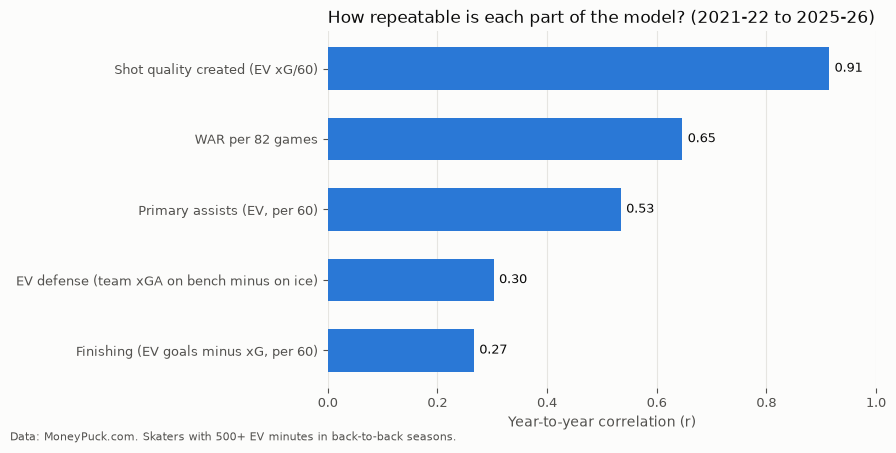

In [6]:
SURFACE, INK, MUTED, BLUE = "#fcfcfb", "#0b0b0b", "#52514e", "#2a78d6"

plot = repeatability.sort_values()
fig, ax = plt.subplots(figsize=(9, 4.5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.barh(plot.index, plot.values, color=BLUE, height=0.6)
for y, v in enumerate(plot.values):
    ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=9, color=INK)
ax.set_xlim(0, 1)
ax.set_xlabel("Year-to-year correlation (r)", color=MUTED)
ax.set_title("How repeatable is each part of the model? (2021-22 to 2025-26)", loc="left", color=INK, fontsize=12)
ax.tick_params(colors=MUTED, labelsize=9)
ax.grid(axis="x", color="#e6e5e1", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ax.spines.values():
    spine.set_visible(False)
fig.text(0.01, 0.01, "Data: MoneyPuck.com. Skaters with 500+ EV minutes in back-to-back seasons.", fontsize=8, color=MUTED)
plt.tight_layout()
fig.savefig(IMAGES / "repeatability.png", dpi=150, facecolor=SURFACE)
plt.show()

**Question for you:** which components are mostly skill and which are mostly noise? What does that say about how much weight each one should get in v0.4?

## 5. The Caufield question
In v0.3, Caufield ranked #2 largely because he scored 33 even-strength goals on about 18 expected. The guess was that this was mostly luck. Five seasons can test that.

In [7]:
caufield = df[df["name"] == "Cole Caufield"].copy()
caufield["goals_minus_xg"] = caufield["ev_I_F_goals"] - caufield["ev_I_F_xGoals"]
caufield[["season", "team", "games_played", "ev_I_F_goals", "ev_I_F_xGoals", "goals_minus_xg", "war", "war_rank"]].round(2)

,season,team,games_played,ev_I_F_goals,ev_I_F_xGoals,goals_minus_xg,war,war_rank
836,2021,MTL,67,15.0,11.43,3.57,0.72,194
1807,2022,MTL,46,17.0,9.58,7.42,0.69,187
2811,2023,MTL,82,16.0,17.20,-1.20,1.77,61
3483,2024,MTL,82,26.0,18.81,7.19,2.35,28
4731,2025,MTL,81,33.0,18.07,14.93,3.99,2


In [8]:
total = caufield[["ev_I_F_goals", "ev_I_F_xGoals"]].sum()
print(f"Five seasons combined: {total['ev_I_F_goals']:.0f} EV goals on {total['ev_I_F_xGoals']:.1f} expected "
      f"({total['ev_I_F_goals'] - total['ev_I_F_xGoals']:+.1f})")

Five seasons combined: 107 EV goals on 75.1 expected (+31.9)


**Question for you:** finishing as a stat has low repeatability across the league, but look at Caufield's own history. Is he lucky, or is he a real elite finisher? How should the model handle a player like him?

## 6. Stars across seasons

In [9]:
STARS = ["Connor McDavid", "Nathan MacKinnon", "Auston Matthews", "Leon Draisaitl", "Cale Makar",
         "Cole Caufield", "Lane Hutson"]

(df[df["name"].isin(STARS)]
   .pivot_table(index="name", columns="season", values="war_rank", aggfunc="first")
   .reindex(STARS))

season,2021,2022,2023,2024,2025
name,,,,,
Connor McDavid,2.0,1.0,2.0,3.0,1.0
Nathan MacKinnon,11.0,17.0,3.0,23.0,4.0
Auston Matthews,1.0,5.0,1.0,4.0,57.0
Leon Draisaitl,6.0,2.0,26.0,5.0,5.0
Cale Makar,19.0,20.0,22.0,1.0,10.0
Cole Caufield,194.0,187.0,61.0,28.0,2.0
Lane Hutson,NaN,NaN,375.0,131.0,9.0


## 7. Save
`war_by_season.csv` has every skater's WAR and components for all five seasons. This is the base table for the player cards and for aging curves later.

In [10]:
keep = ["season", "playerId", "name", "team", "position", "pos_group", "games_played",
        "all_toi", "ev_toi", "pp_toi", "pk_toi"] + COMPONENTS + ["gar", "war", "war_rank"]
all_seasons[keep].to_csv(DATA / "war_by_season.csv", index=False)
print("Saved", len(all_seasons), "player-seasons to data/war_by_season.csv")

Saved 4738 player-seasons to data/war_by_season.csv


## Takeaways for v0.4
- Fill in after answering the questions above.